In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_excel('/content/1776311688-P5-Exploring Global Terrorism Patterns & Trends.xlsx', sheet_name='Combined raw')

In [3]:
df.head()

,iso3c,Country,Rank,Score,Incidents,Fatalities,Injuries,Hostages,Year
0,IRQ,Iraq,1,9.599967,1288,2086,5050,16,2012
1,PAK,Pakistan,2,9.152620,638,1322,2297,160,2012
2,AFG,Afghanistan,3,9.134265,507,1511,2612,67,2012
3,SYR,Syria,4,8.238079,168,1014,1833,71,2012
4,YEM,Yemen,5,8.098513,219,651,798,121,2012


In [4]:
df.tail()

,iso3c,Country,Rank,Score,Incidents,Fatalities,Injuries,Hostages,Year
1788,TKM,Turkmenistan,93,0.0,0,0,0,0,2022
1789,TLS,Timor-Leste,93,0.0,0,0,0,0,2022
1790,TTO,Trinidad and Tobago,93,0.0,0,0,0,0,2022
1791,ZMB,Zambia,93,0.0,0,0,0,0,2022
1792,ZWE,Zimbabwe,93,0.0,0,0,0,0,2022


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1793 entries, 0 to 1792
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   iso3c       1793 non-null   object 
 1   Country     1793 non-null   object 
 2   Rank        1793 non-null   int64  
 3   Score       1793 non-null   float64
 4   Incidents   1793 non-null   int64  
 5   Fatalities  1793 non-null   int64  
 6   Injuries    1793 non-null   int64  
 7   Hostages    1793 non-null   int64  
 8   Year        1793 non-null   int64  
dtypes: float64(1), int64(6), object(2)
memory usage: 126.2+ KB


In [6]:
df.describe()

,Rank,Score,Incidents,Fatalities,Injuries,Hostages,Year
count,1793.000000,1793.000000,1793.000000,1793.000000,1793.000000,1793.000000,1793.00000
mean,71.691578,2.442817,26.699944,53.537646,74.588957,10.149470,2017.00000
std,35.235705,2.654876,109.500965,253.912698,415.669549,82.306937,3.16316
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2012.00000
25%,41.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2014.00000
50%,82.000000,1.534965,0.000000,0.000000,0.000000,0.000000,2017.00000
75%,106.000000,4.419243,4.000000,2.000000,4.000000,0.000000,2020.00000
max,112.000000,10.000000,1673.000000,4514.000000,9479.000000,2727.000000,2022.00000


# Checking null values


In [7]:
df.isnull().sum()

,0
iso3c,0
Country,0
Rank,0
Score,0
Incidents,0
Fatalities,0
Injuries,0
Hostages,0
Year,0


# Exploratory Data Anaysis


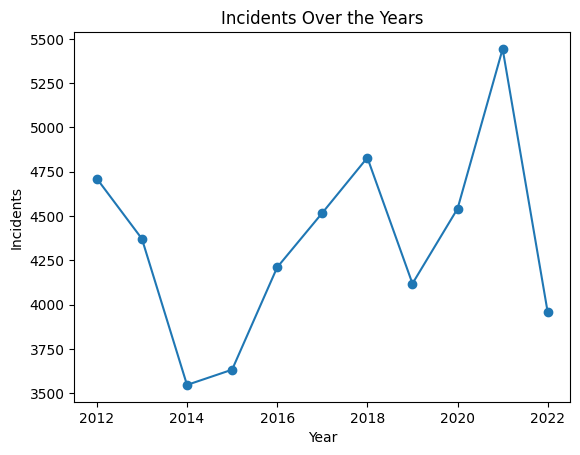

In [8]:
yearly_incidents = df.groupby('Year')['Incidents'].sum().reset_index()
plt.plot(yearly_incidents['Year'],yearly_incidents['Incidents'], marker='o', linestyle='-')
plt.xlabel('Year')
plt.ylabel('Incidents')
plt.title('Incidents Over the Years')
plt.show()

Insight

1. The graph show an overall upward trend in the total number of incidents over this period, indicating an increase in terrorism incidents worldwide.

2. The year 2020 stands out with the highest number of incidents.

3. The year 2014 had the lowest number of incidents, with just over 3500. This indicates a relatively peaceful period compared to other years.

4. There's is sharpe increase in incidents from 2018 to 2020, which might suggest a period of hightened global conflicts or instability




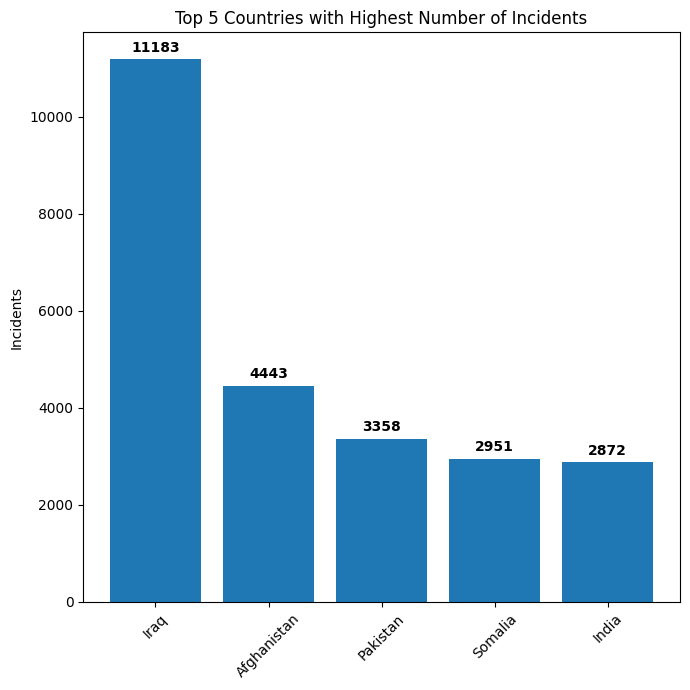

In [9]:
country_wise_incidents = df.groupby('Country')['Incidents'].sum().reset_index()

top_5_countries = country_wise_incidents.nlargest(5, 'Incidents')

plt.figure(figsize=(7, 7))
bars = plt.bar(top_5_countries['Country'], top_5_countries['Incidents'])

# Adding value labels on top of each bar
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 100, f'{int(yval)}', ha='center', va='bottom', fontweight='bold')

plt.ylabel('Incidents')
plt.title('Top 5 Countries with Highest Number of Incidents')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Insight


1. Iraq has the heighest number of incidents, with total of 11183 incidents.This suggest that Iraq has been the most affected by these incidents.

2. Afghanistan follows the next with 4,443 incidents, which is less than half of those in Iraq but still.

3. Pakistan and Somalia have also experienced a high number of incidents, with 3,358 and 2,951 respectively

4. India is also in the top 5 list with 2,872 incidents.


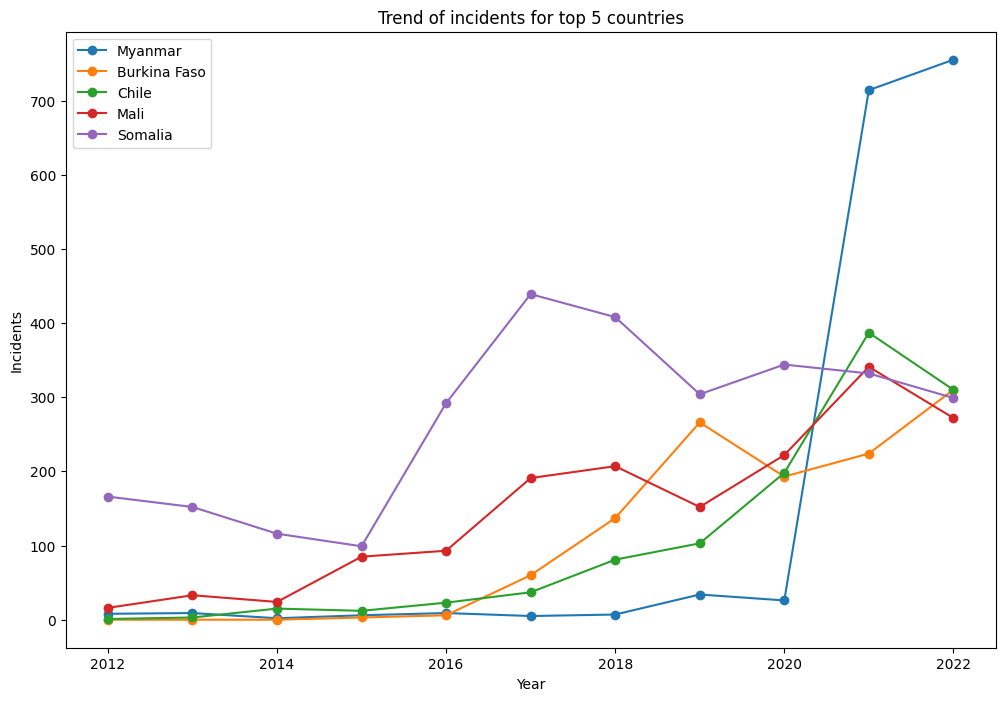

In [10]:
from pandas.core.reshape.api import pivot_table
#Ensure Year column is treated as integer
df['Year']=df['Year'].astype(int)

#Grouping the data by year and country and finding totol incidents
yearly_totals = df.groupby(['Year','Country'])['Incidents'].sum().reset_index()

#Pivot Table
pivot_table=yearly_totals.pivot(values='Incidents', index='Country', columns='Year').fillna(0)

#Calculate the increase in incidents for each country from 2012 to 2022
increase=pivot_table[2022]-pivot_table[2012]

#top 5 country based on increase in incidents
top_5_countries=increase.nlargest(5).index


#Filters a pivot_table to pull out the full records for just those 5 countries.
top_countries_data = pivot_table.loc[top_5_countries]

#Creating a line chart to visulaize this
plt.figure(figsize=(12,8))
for country in top_countries_data.index:
  plt.plot(top_countries_data.columns, top_countries_data.loc[country], marker='o', label=country)

plt.title('Trend of incidents for top 5 countries')
plt.xlabel('Year')
plt.ylabel('Incidents')
plt.legend()
plt.show()





Insights

1. **Myanmar** shows the highest increase in incidents, with a sharp rise from 2012 to 2022. This suggests a significant escalation in incidents during this period

2. Both **Burkina** **Faso** and **Mali** shows a steady increase in incidents over the years, indicating a persistent issue in these countries.

3. **Chile** shows a slight increase in incidents from 2012 to 2018, but then a decrease from 2018 to 2022. This could indicate an improvement in the situation or effective countermeasures implemented

4. **Somlia** show a slight increase in the incidents over the years, suggesting a gradual escalation.

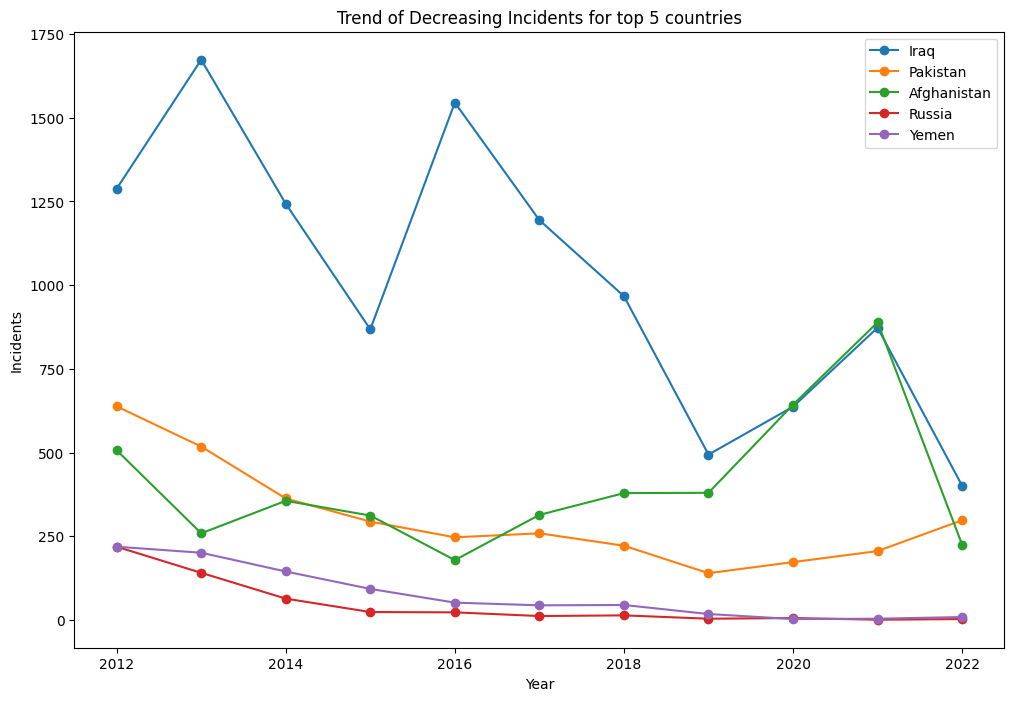

In [11]:
df['Year']=df['Year'].astype(int)

#group the data by country and year and calculate the total incidents
yearly_totals=df.groupby(['Country', 'Year'])['Incidents'].sum().reset_index()

#Pivot Table
pivot_table=yearly_totals.pivot(values='Incidents', index='Country', columns='Year').fillna(0)

#Calculate the decrease in incidents for each country from 2012 to 2022
decrease=pivot_table[2012]-pivot_table[2022]

#top 5 countries with highest number of decrease in incidents
top_5_countries=decrease.nlargest(5).index

#Filters a pivot_table to pull out the full records for just those 5 countries
top_countries_data=pivot_table.loc[top_5_countries]

#Creating a line chart to visulaize this
plt.figure(figsize=(12,8))

for country in top_countries_data.index:
  plt.plot(top_countries_data.columns, top_countries_data.loc[country], marker='o', label=country)

plt.title('Trend of Decreasing Incidents for top 5 countries')
plt.xlabel('Year')
plt.ylabel('Incidents')
plt.legend()
plt.show()



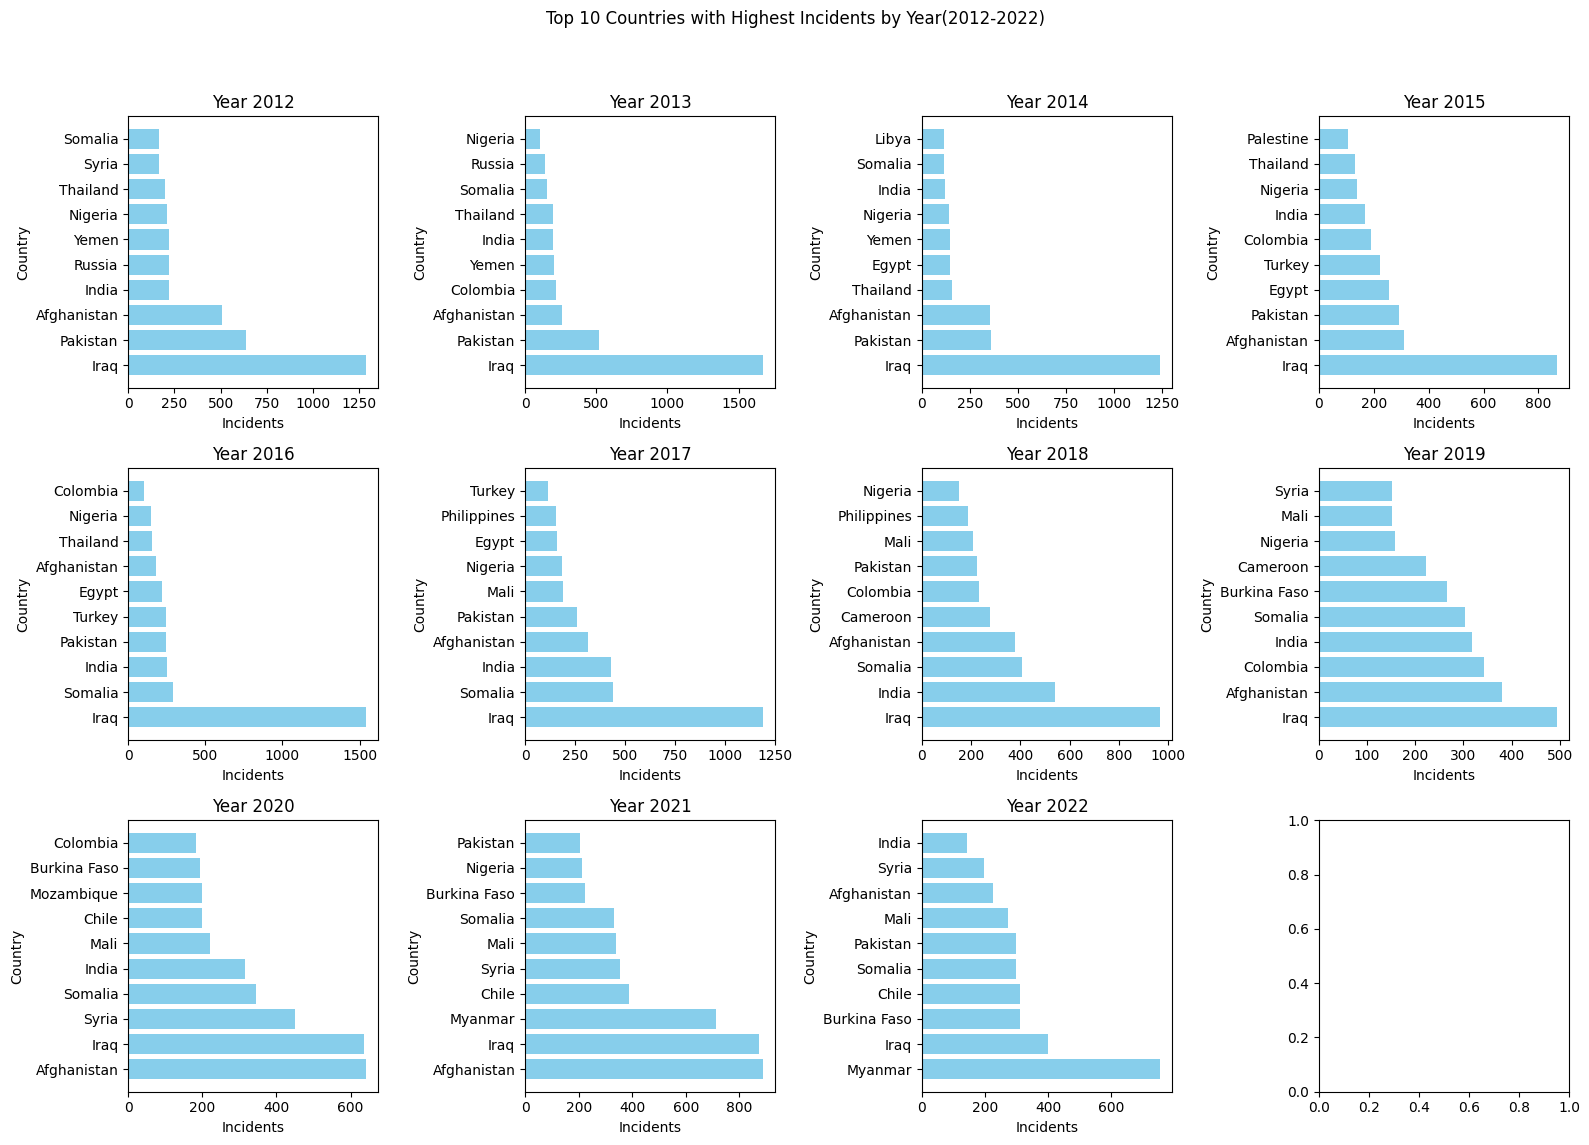

In [12]:
df['Year']=df['Year'].astype(int)

#Initialze an empty Dataframe to Store a Result
top_countries_by_year=pd.DataFrame(columns=['Country','Year','Incidents'])

#Create a figure with subplots for each year
fig,axs=plt.subplots(nrows=3, ncols=4, figsize=(16,12))
fig.suptitle('Top 10 Countries with Highest Incidents by Year(2012-2022)')

#Loop through the years from 2012 to 2022
for i, years in enumerate(range(2012, 2023)):
  #Filter the data for the current year
  yearly_data=df[df['Year']==years]

  #Group the data by country and calculate sum of incidents
  top_countries_year = yearly_data.groupby('Country')['Incidents'].sum().reset_index()

  #Sort the data by incidents in descending order to get the top 10 countries
  top_10_countries_year=top_countries_year.nlargest(10, 'Incidents')

  #Add the year to the result
  top_10_countries_year['Year']=years

  #Concate the result for the current year to the overall results Dataframe
  top_countries_by_year=pd.concat([top_countries_by_year, top_10_countries_year], ignore_index=True)

  #Create a bar chart for current year
  row, column= i//4, i%4
  ax=axs[row,column]
  ax.barh(top_10_countries_year['Country'], top_10_countries_year['Incidents'], color='skyblue')
  ax.set_title(f'Year {years}')
  ax.set_xlabel('Incidents')
  ax.set_ylabel('Country')

#Adjust Layout
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

Insights

1. The countries that consistently apper in the top 10 across these years are **Afghanistan**, **Pakistan**, **Iraq**. This suggest that these countries have been persistenly affected by these incidents over this period.

In [13]:
total_fatalities_by_year= df.groupby('Year')['Fatalities'].sum().reset_index()
top_10_countries=total_fatalities_by_year.nlargest(5, 'Fatalities')
print(top_10_countries)


   Year  Fatalities
3  2015       10881
4  2016       10372
1  2013       10317
2  2014       10129
0  2012        9227


Insights

1. The year 2015 has heighest number of fatalities, with a total of 10881. This suggest that 2015 was the most deadly year among those listed

2. 2016 follows next with 10372 fatalities, which is slightly less than 2015 but still significant.

3. Year 2013 and 2014 also had a high number of fatalities with 10317 and 10129 respectively.

4. 2012 also listed in top 5 list with a total of 9227 fatalities.

In [14]:
df['Year']=df['Year'].astype(int)

#Filtre the dataset for year 2015
fatalities_2015=df[(df['Year']==2015)]

#Group the data by country and calculate the sum of fatalities for 2015
fatalities_2015_by_country=fatalities_2015.groupby('Country')['Fatalities'].sum().reset_index()

#finding the top 10 countries with highest number of fatalities in 2015
top_10_countries=fatalities_2015_by_country.nlargest(10, 'Fatalities')
print(top_10_countries)



         Country  Fatalities
66          Iraq        2974
105      Nigeria        2003
0    Afghanistan        1008
109     Pakistan         658
41         Egypt         481
160        Yemen         458
130      Somalia         335
23      Cameroon         292
149       Turkey         286
83         Libya         234


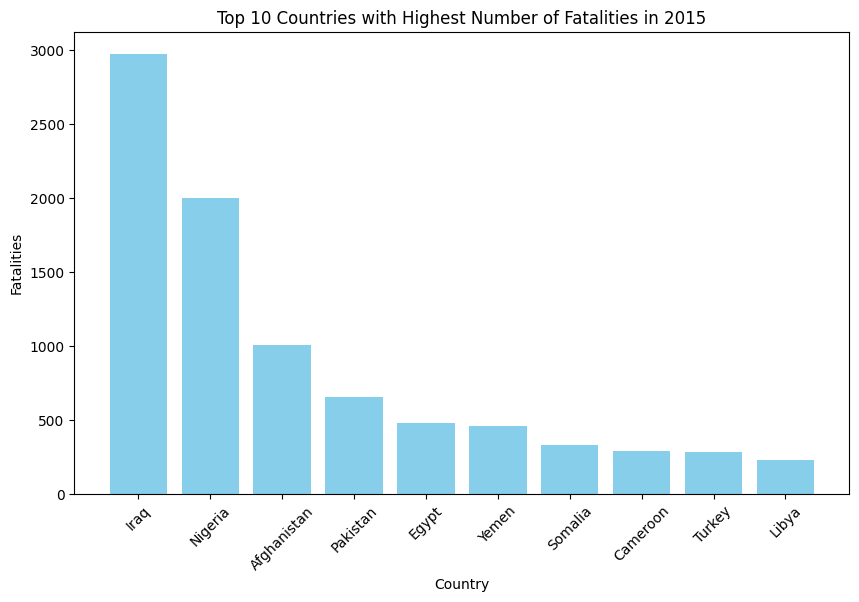

In [15]:
df['Year']=df['Year'].astype(int)

#Filtre the dataset for year 2015
fatalities_2015=df[(df['Year']==2015)]

#Group the data by country and calculate the sum of fatalities for 2015
fatalities_2015_by_country=fatalities_2015.groupby('Country')['Fatalities'].sum().reset_index()

#finding the top 10 countries with highest number of fatalities in 2015
top_10_countries=fatalities_2015_by_country.nlargest(10, 'Fatalities')

#creating a bar chart to visualize this
plt.figure(figsize=(10,6))
plt.bar(top_10_countries['Country'], top_10_countries['Fatalities'], color='skyblue')
plt.xlabel('Country')
plt.ylabel('Fatalities')
plt.title('Top 10 Countries with Highest Number of Fatalities in 2015')
plt.xticks(rotation=45)
plt.show()

Insights

1. **Iraq** had the highest number of fatalities, with total of 2,974. This shows that Iraq was the most affected by these incidents in 2015.

2. **Nigeria** follows next with 2,003 fatalities which is slightly less than Irag but still significant.

3. **Afghanistan** also had a highest number of fatalities, with 1,008.

4. Other countries like **Pakistan**, **Egypt**, **Yemen**, **Somalia**, **Cameroon**, **Turkey** and **Libya** aslo experienced a considerable number of fatalities ranging from 234 to 658.  

In [16]:
#Filter the dataset for rows where Rank is equal to 1
rank_1_data=df[df['Rank']==1]

#Count the occurence of each unique country with rank 1
rank_1_count= rank_1_data['Country'].value_counts()

#Print the unique countries and their respective count
for country, count in rank_1_count.items():
  print(f'Country: {country}: Count: {count}')

Country: Iraq: Count: 7
Country: Afghanistan: Count: 4


Insights

1. **Iraq** has ranked first 7 times. This suggests that Iraq has frequently been at the top of this ranking.

2. **Afghanistan** has also ranked first, but less frequently than Iraq, with a total of 4 times.

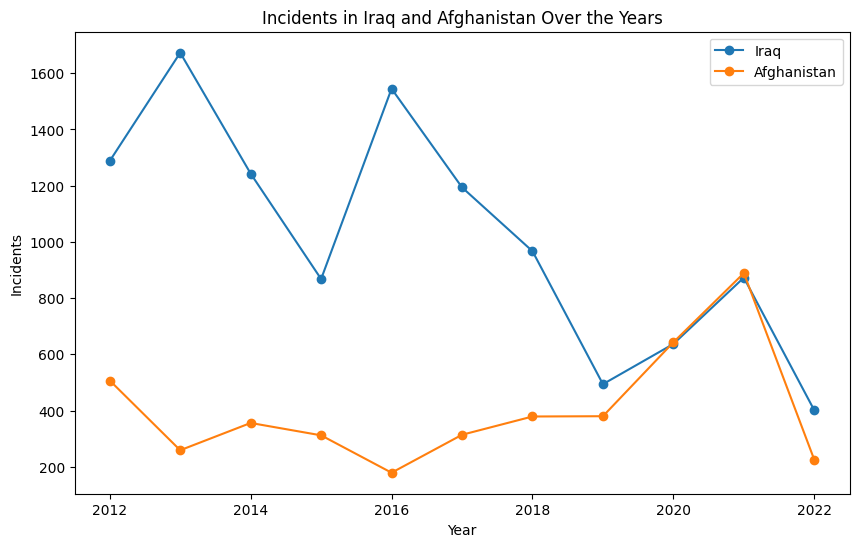

In [17]:
from matplotlib.lines import lineStyles
#Filter the dataset for Iraq and Afghanistan
Iraq_data=df[df['Country']=='Iraq']
Afghanistan_data=df[df['Country']=='Afghanistan']

#Create a line plot to visualize the incidents
plt.figure(figsize=(10,6))
plt.plot(Iraq_data['Year'], Iraq_data['Incidents'], label='Iraq', marker='o', linestyle='-')
plt.plot(Afghanistan_data['Year'], Afghanistan_data['Incidents'], label='Afghanistan', marker='o', linestyle='-')
plt.xlabel('Year')
plt.ylabel('Incidents')
plt.title('Incidents in Iraq and Afghanistan Over the Years')
plt.legend()
plt.show()

Insights

1. **Iraq** shows a downward trend in incidents from 2016 and 2018 respectivily to 2022. This suggests a decrease in these incidents over these periods in both countries.

2. **Iraq** had peak in the number of incidents in 2013 and 2016, suggesting that these years were particularly challenging.

3. **Afghanistan** had a peak in the number of incidents in 2018, indicating a significant increase in incidents during that year.

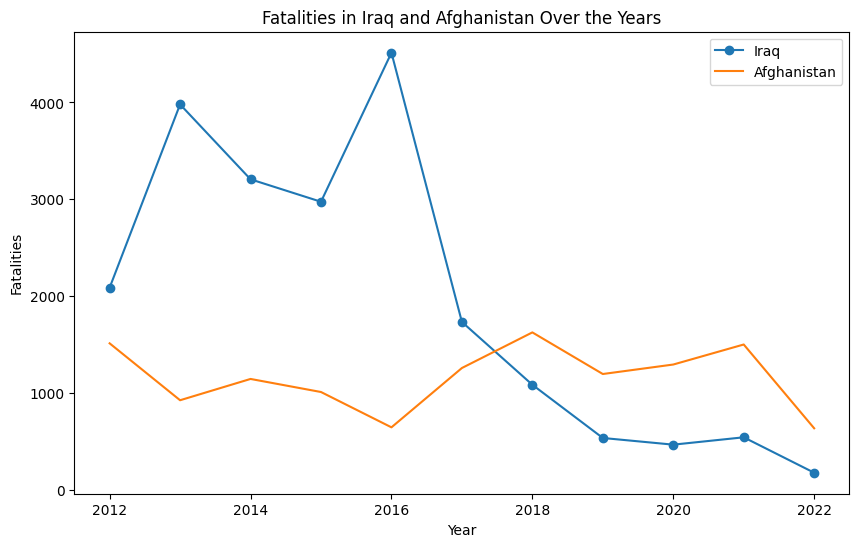

In [18]:
#Filter the dataset for Iraq and Afghanistan
Iraq_data=df[df['Country']=='Iraq']
Afghanistan_data=df[df['Country']=='Afghanistan']

#Create a line plot to visualize the incidents
plt.figure(figsize=(10,6))
plt.plot(Iraq_data['Year'], Iraq_data['Fatalities'], label='Iraq', marker='o', linestyle='-')
plt.plot(Afghanistan_data['Year'], Afghanistan_data['Fatalities'], label='Afghanistan')
plt.title('Fatalities in Iraq and Afghanistan Over the Years')
plt.xlabel('Year')
plt.ylabel('Fatalities')
plt.legend()
plt.show()



Insights

1. Both **Iraq** and **Afghanistan** shows a significant number of fatalities over this period, indicating the severe impact of these incidents in both countries.

2. **Iraq** has the highest number of Fatalities in 2014, with around 4,000. This suggests that 2014 was a particulary deadly year in Iraq.

3. **Afghanistan** had its highest number of fatalities in 2018, with around 3,500, indicating a significant surge in deadly incidents during that year.

In [19]:
#Calculate the correlation matrix
correlation_matrix=df[['Score','Incidents','Fatalities','Injuries','Hostages']].corr()

#Print the correlation matrix
print(correlation_matrix)

               Score  Incidents  Fatalities  Injuries  Hostages
Score       1.000000   0.516868    0.479365  0.410757  0.263119
Incidents   0.516868   1.000000    0.860467  0.863206  0.282083
Fatalities  0.479365   0.860467    1.000000  0.912888  0.318144
Injuries    0.410757   0.863206    0.912888  1.000000  0.317053
Hostages    0.263119   0.282083    0.318144  0.317053  1.000000


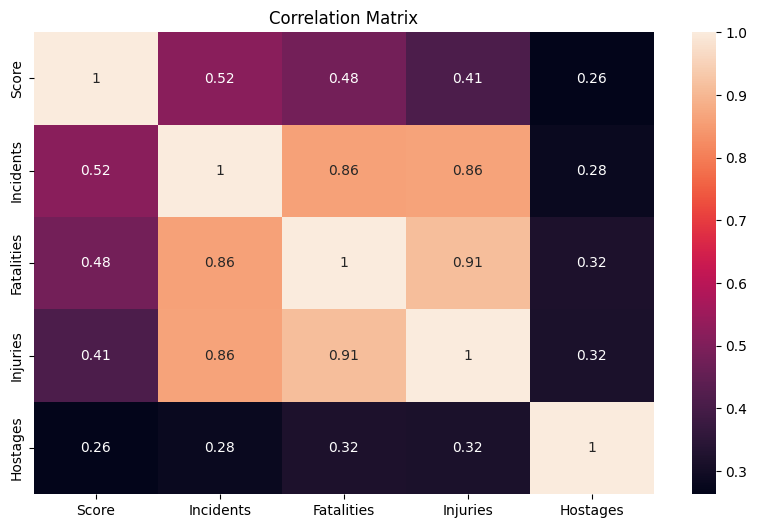

In [20]:
#Print the heatmap to visualize above correlation matrix
plt.figure(figsize=(10,6))
sns.heatmap(correlation_matrix, annot=True)
plt.title('Correlation Matrix')
plt.show()

Insights

1. **Incidents** and **Fatalities** have a higher correlation of 0.86 suggesting that as the number of incidents increases,the number of fatalities tends to increase as well.

2. Similarly, **Incidents** and **Injuries** have a high correlation of 0.86, indicating a strong positive relationship between these two variables.

3. **Fatalities** and **Injuries** also have high correlation of 0.91, which is the highest in this matrix. This suggests that incidents with more fatalities also tend to have more injuries.

4. **Hostages** has the lowest correlations with all other variables, suggesting that the number of hostages taken may not been strongly influenced by the other variables in this dataset.

#**Conclusion**

Based on the analysis of the data and graphs, it can be concluded that from 2012 to 2022, countries like Iraq and Afghanistan experienced a significant number of incidents and fatalities. However, there has been a decreasing trend in recent years, suggesting an improvement in the situation. The correlation matrix indicates a strong positive relationship between the number of incidents, fatalities, and injuries, suggesting that incidents with a higher number of fatalities also tend to have more injuries. Despite these correlations, the number of hostages taken does not seem to be strongly influenced by these other variables. It's important to note that these insights are based on the available data and do not account for all possible factors. The complexity of these issues means that additional context and analysis would be beneficial for a more comprehensive understanding. Furthermore, while these variables show a strong correlation, it doesn't necessarily mean that one variable's increase causes an increase in the other as correlation does not imply causation. Other factors could be influencing these relationships.